# Experiment 1: compare approaches
This notebook reads only completed portable analysis summaries and histogram CSV files. It never opens raw recordings, models, or simulator code. Loading ranges and motion selections are compared separately.

In [6]:
import os, json, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Find this checkout whether Jupyter starts in the repository or notebooks directory.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "exp1_analysis.py").exists())
sys.path.insert(0, str(REPO / "notebooks"))
import exp1_analysis as exp1
# Refresh helper changes even when this Jupyter kernel was already running.
import importlib
exp1 = importlib.reload(exp1)

CONFIG = {
    "summary_roots": [str(REPO / "analysis/exp1")],
    "output_dir": str(REPO / "analysis/exp1_comparison/in_locomotion"),
    "method_order": [
        "b1z1_unifp_original", "b1z1_ppo_pos",
        "b1z1_pact_ab4_coupled_none", "b1z1_pact_ab5_coupled_concat",
        "b1z1_pact_ab6_position_film", "b1z1_pact_ab7_position_full",
        "b1z1_pact_ab8_coupled_film", "b1z1_pact_ab9_representation",
        "b1z1_pact_ab10_actor", "b1z1_pact"],
    "display_names": {"b1z1_pact": "PILOT", "b1z1_unifp_original": "UniFP", "b1z1_ppo_pos": "Pos"},
    "focused_methods": ["b1z1_pact", "b1z1_unifp_original", "b1z1_ppo_pos"],
    "load_range": "in",  # Analyze "out" separately.
    "motion": "combined",  # "stationary", "locomotion", or explicitly exported "combined".
    "response_table": True,
    "optional_metrics": [],  # e.g. ["torso_angular_acceleration_rms", "ee_linear_acceleration_rms"]
    "additional_plots": ["step", "ecdf", "box"],  # Set [] to export only the original histogram.
}
if os.environ.get("EXP1_COMPARE_CONFIG"):
    CONFIG.update(json.loads(Path(os.environ["EXP1_COMPARE_CONFIG"]).read_text()))
CONFIG


{'summary_roots': ['/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1'],
 'output_dir': '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1_comparison/in_locomotion',
 'method_order': ['b1z1_unifp_original',
  'b1z1_ppo_pos',
  'b1z1_pact_ab4_coupled_none',
  'b1z1_pact_ab5_coupled_concat',
  'b1z1_pact_ab6_position_film',
  'b1z1_pact_ab7_position_full',
  'b1z1_pact_ab8_coupled_film',
  'b1z1_pact_ab9_representation',
  'b1z1_pact_ab10_actor',
  'b1z1_pact'],
 'display_names': {'b1z1_pact': 'PILOT',
  'b1z1_unifp_original': 'UniFP',
  'b1z1_ppo_pos': 'Pos'},
 'focused_methods': ['b1z1_pact', 'b1z1_unifp_original', 'b1z1_ppo_pos'],
 'load_range': 'in',
 'motion': 'combined',
 'response_table': True,
 'optional_metrics': [],
 'additional_plots': ['step', 'ecdf', 'box']}

## Validation and tables
Protocols, units, histogram bins/frames and seed coverage must agree. Duplicate method summaries are rejected. Missing results display as an em dash. Each cell reports **mean ± sample SD across evaluation seeds**; tracking/failure/recovery fractions are displayed as percentages.

CSV and LaTeX tables are exported. The main table uses text width; focused tables use column width (`graphicx` and `booktabs` required). Times New Roman is used for figures if installed, with a serif fallback.

In [7]:
tables, figure, diagnostics = exp1.compare(CONFIG)
for name, table in tables.items():
    print(name)
    display(table)
print("\n".join(diagnostics) or "Compatible complete comparison.")


main


nominal                                \
                                     EE [m] Velocity [m/s]    Yaw [rad/s]   
UniFP                         0.031 ± 0.000  0.039 ± 0.001  0.065 ± 0.001   
Pos                                       —              —              —   
b1z1_pact_ab4_coupled_none                —              —              —   
b1z1_pact_ab5_coupled_concat              —              —              —   
b1z1_pact_ab6_position_film               —              —              —   
b1z1_pact_ab7_position_full               —              —              —   
b1z1_pact_ab8_coupled_film                —              —              —   
b1z1_pact_ab9_representation              —              —              —   
b1z1_pact_ab10_actor                      —              —              —   
PILOT                         0.022 ± 0.000  0.053 ± 0.001  0.066 ± 0.000   

                                                            ee-disturbance  \
                                Tracking [%]    Failure [%]         EE [m]   
UniFP                         98.718 ± 0.029  0.000 ± 0.000  0.082 ± 0.001   
Pos                                        —              —              —   
b1z1_pact_ab4_coupled_none                 —              —              —   
b1z1_pact_ab5_coupled_concat               —              —              —   
b1z1_pact_ab6_position_film                —              —              —   
b1z1_pact_ab7_position_full                —              —              —   
b1z1_pact_ab8_coupled_film                 —              —              —   
b1z1_pact_ab9_representation               —              —              —   
b1z1_pact_ab10_actor                       —              —              —   
PILOT                         98.626 ± 0.027  0.000 ± 0.000  0.062 ± 0.001   

                                                                            \
                             Velocity [m/s]    Yaw [rad/s]    Tracking [%]   
UniFP                         0.061 ± 0.000  0.092 ± 0.000  72.851 ± 1.408   
Pos                                       —              —               —   
b1z1_pact_ab4_coupled_none                —              —               —   
b1z1_pact_ab5_coupled_concat              —              —               —   
b1z1_pact_ab6_position_film               —              —               —   
b1z1_pact_ab7_position_full               —              —               —   
b1z1_pact_ab8_coupled_film                —              —               —   
b1z1_pact_ab9_representation              —              —               —   
b1z1_pact_ab10_actor                      —              —               —   
PILOT                         0.072 ± 0.000  0.114 ± 0.002  78.191 ± 0.660   

                                            combined-disturbance  \
                                Failure [%]               EE [m]   
UniFP                         8.667 ± 3.055        0.082 ± 0.001   
Pos                                       —                    —   
b1z1_pact_ab4_coupled_none                —                    —   
b1z1_pact_ab5_coupled_concat              —                    —   
b1z1_pact_ab6_position_film               —                    —   
b1z1_pact_ab7_position_full               —                    —   
b1z1_pact_ab8_coupled_film                —                    —   
b1z1_pact_ab9_representation              —                    —   
b1z1_pact_ab10_actor                      —                    —   
PILOT                         0.333 ± 0.577        0.062 ± 0.001   

                                                                            \
                             Velocity [m/s]    Yaw [rad/s]    Tracking [%]   
UniFP                         0.069 ± 0.001  0.096 ± 0.001  72.533 ± 1.125   
Pos                                       —              —               —   
b1z1_pact_ab4_coupled_none                —              —               —   
b1z1_pact_ab5_coupled_concat  

physical_limits


Saturation [%]   Position [%]   Velocity [%]
Method       Condition                                                        
PILOT        nominal               0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
             ee-disturbance        0.037 ± 0.004  0.109 ± 0.023  0.000 ± 0.000
             combined-disturbance  0.037 ± 0.006  0.111 ± 0.010  0.000 ± 0.000
UniFP        nominal               0.018 ± 0.001  0.000 ± 0.000  0.000 ± 0.000
             ee-disturbance        0.033 ± 0.001  0.118 ± 0.025  0.001 ± 0.000
             combined-disturbance  0.034 ± 0.001  0.118 ± 0.020  0.001 ± 0.000
b1z1_ppo_pos nominal                           —              —              —
             ee-disturbance                    —              —              —
             combined-disturbance              —              —              —

disturbance_response


Peak EE [m]   Recovery [s]  \
Method       Condition                                            
PILOT        ee-disturbance        0.174 ± 0.002  0.387 ± 0.027   
             combined-disturbance  0.175 ± 0.002  0.389 ± 0.042   
UniFP        ee-disturbance        0.313 ± 0.003  0.704 ± 0.021   
             combined-disturbance  0.317 ± 0.006  0.730 ± 0.014   
b1z1_ppo_pos ee-disturbance                    —              —   
             combined-disturbance              —              —   

                                    Recovered [%]  
Method       Condition                             
PILOT        ee-disturbance        73.000 ± 1.732  
             combined-disturbance  65.556 ± 1.895  
UniFP        ee-disturbance        56.000 ± 2.517  
             combined-disturbance  55.667 ± 1.000  
b1z1_ppo_pos ee-disturbance                     —  
             combined-disturbance               —

Missing b1z1_pact_ab10_actor/combined-disturbance/in/combined/S_track
Missing b1z1_pact_ab10_actor/combined-disturbance/in/combined/ee_error_m
Missing b1z1_pact_ab10_actor/combined-disturbance/in/combined/failure_rate
Missing b1z1_pact_ab10_actor/combined-disturbance/in/combined/planar_velocity_error_m_s
Missing b1z1_pact_ab10_actor/combined-disturbance/in/combined/yaw_error_rad_s
Missing b1z1_pact_ab10_actor/ee-disturbance/in/combined/S_track
Missing b1z1_pact_ab10_actor/ee-disturbance/in/combined/ee_error_m
Missing b1z1_pact_ab10_actor/ee-disturbance/in/combined/failure_rate
Missing b1z1_pact_ab10_actor/ee-disturbance/in/combined/planar_velocity_error_m_s
Missing b1z1_pact_ab10_actor/ee-disturbance/in/combined/yaw_error_rad_s
Missing b1z1_pact_ab10_actor/nominal/in/combined/S_track
Missing b1z1_pact_ab10_actor/nominal/in/combined/ee_error_m
Missing b1z1_pact_ab10_actor/nominal/in/combined/failure_rate
Missing b1z1_pact_ab10_actor/nominal/in/combined/planar_velocity_error_m_s
Missing 

## Signed EE-error distributions
Overlaid histogram bars show equal-seed mean percentage of samples per bin; error bars show sample SD across seeds. These are bin probabilities, not density curves. Rows are x/y/z; columns are nominal and combined disturbances. All methods share bins and axes. Tails are preserved in the histogram exports and `ee_distribution_data.csv`; probabilities are **not** renormalized to hide tails. Vector PDF and PNG are exported alongside tables.

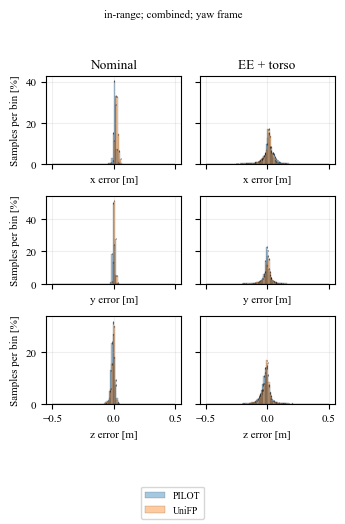

step


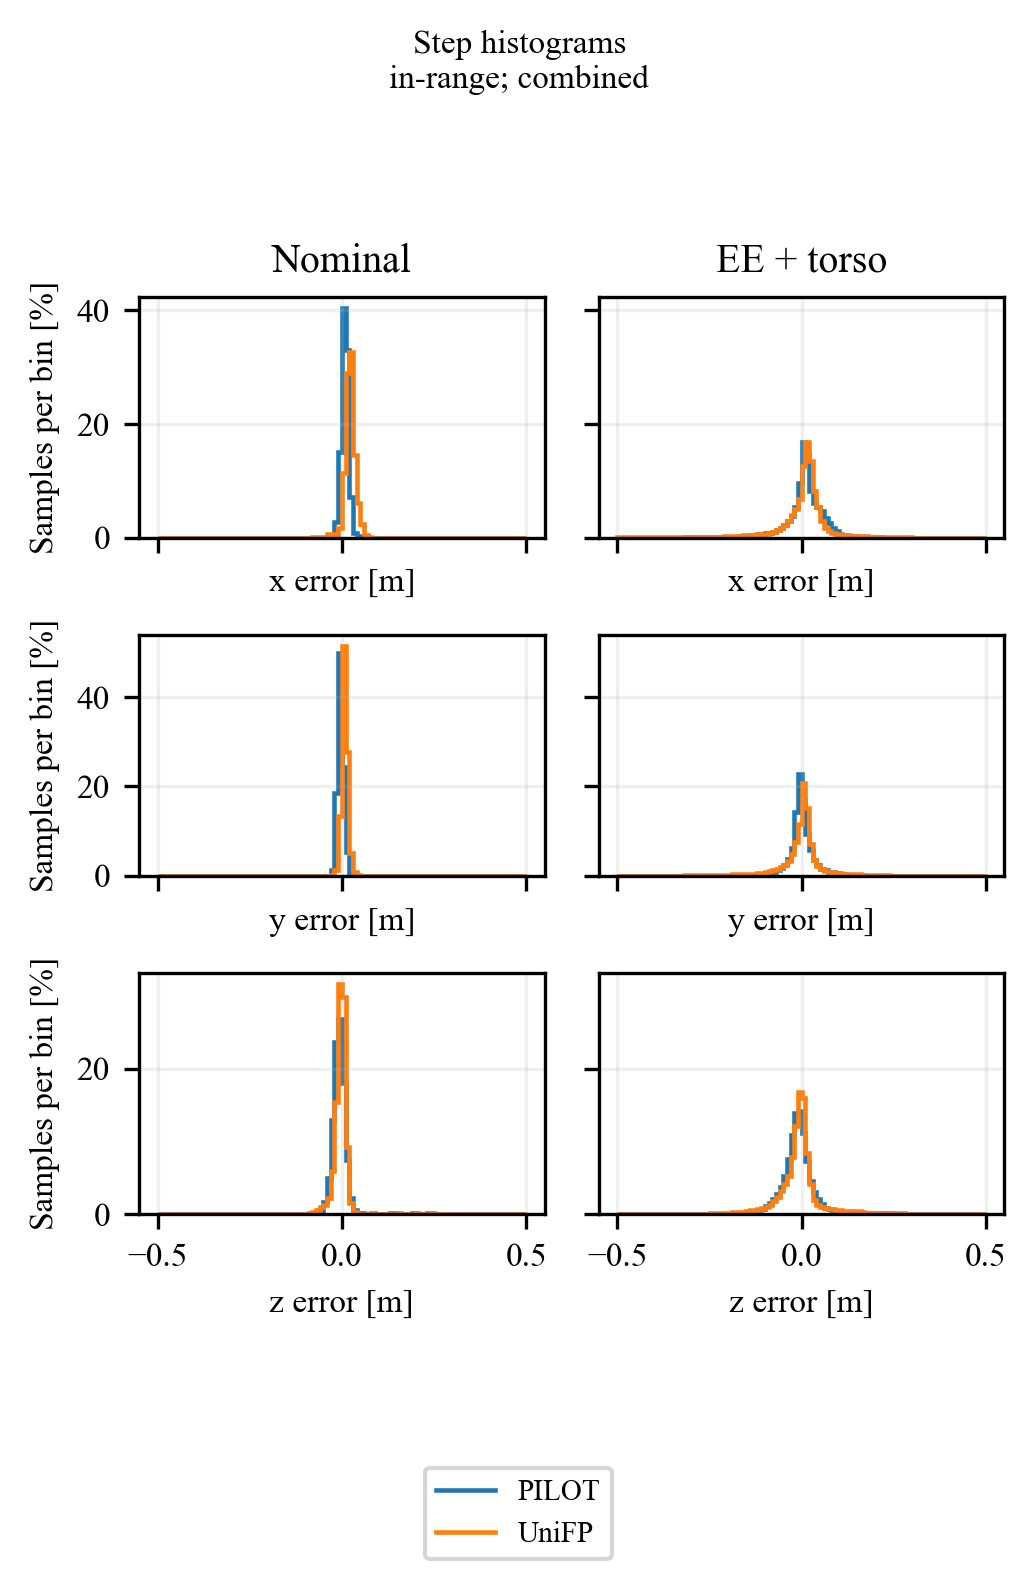

ecdf


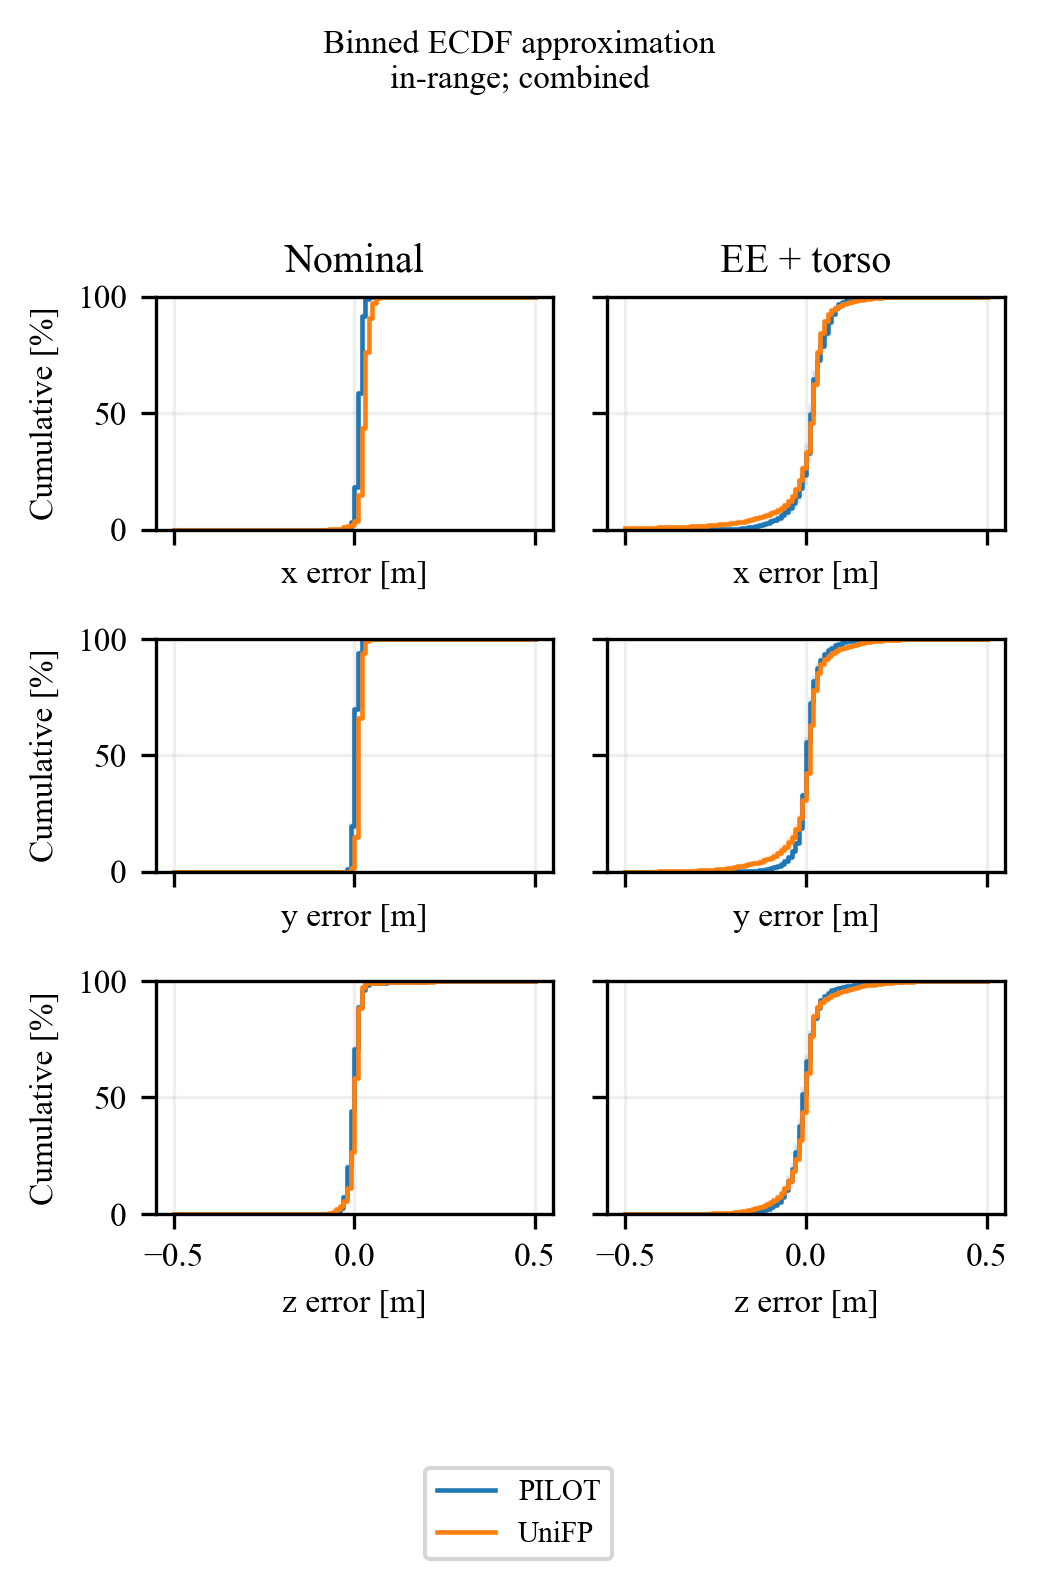

box


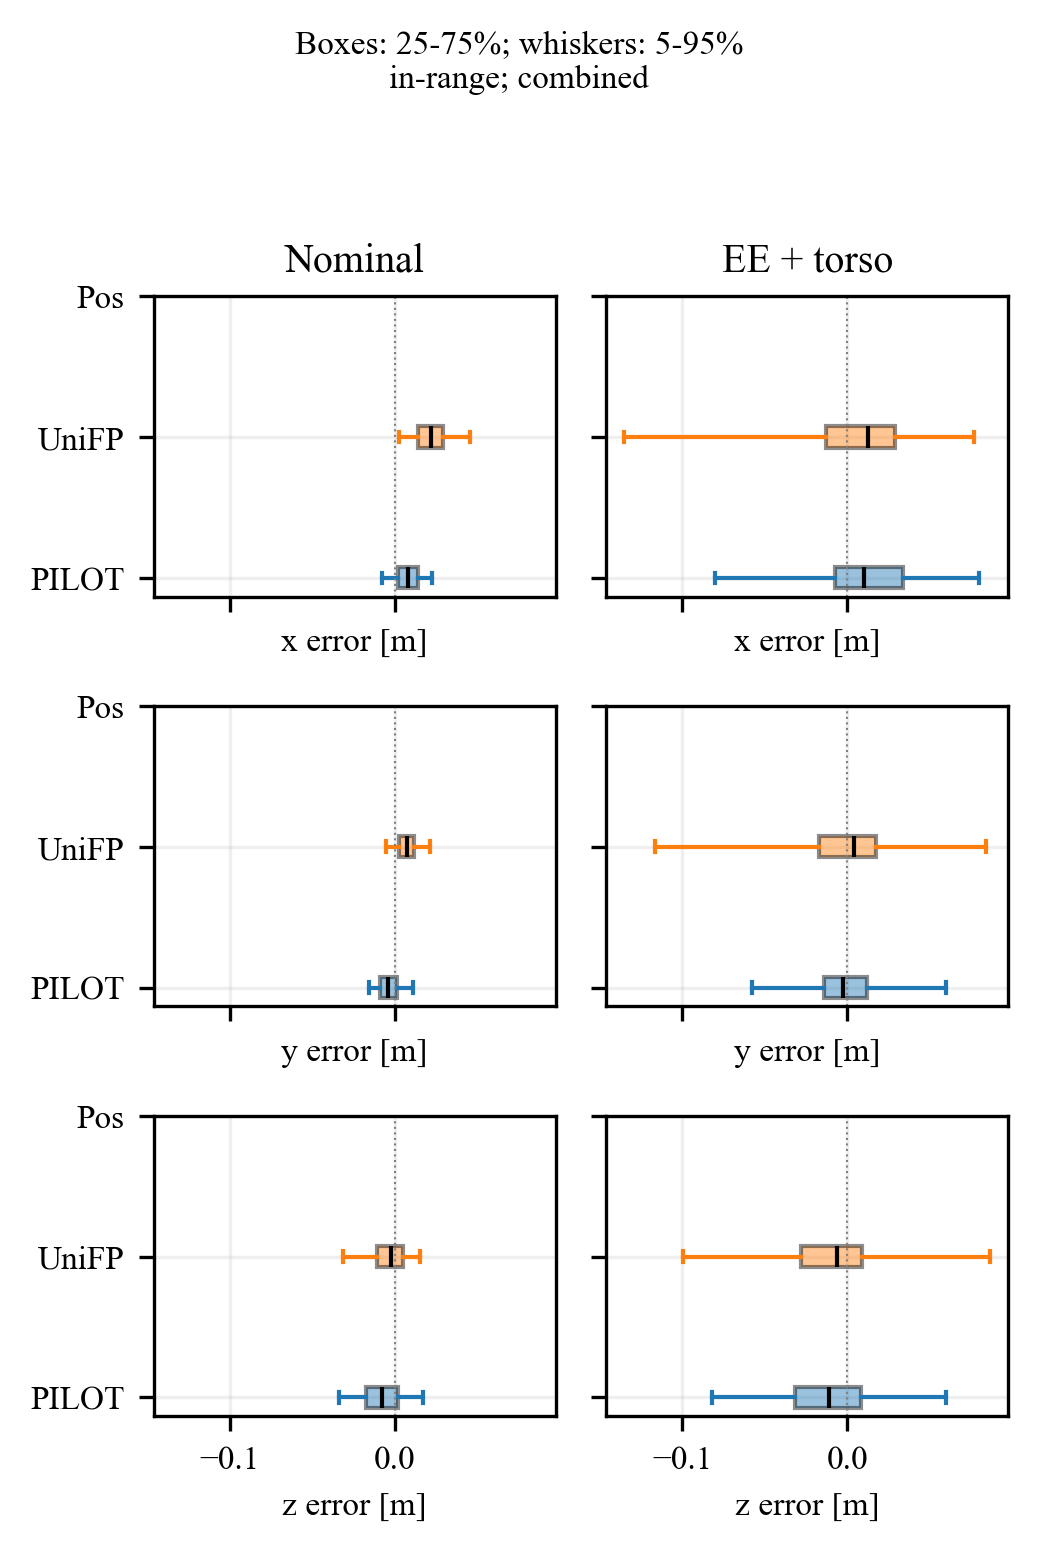

Exported: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1_comparison/in_locomotion


In [8]:
display(figure)
# ECDF is binned; exact equal-seed box statistics require rerunning the summarization notebook.
# Boxes show median and 25-75% spread; whiskers are 5-95%, not Tukey fences or confidence intervals.
from IPython.display import Image
for kind in CONFIG.get("additional_plots", ["step", "ecdf", "box"]):
    print(kind)
    display(Image(filename=str(Path(CONFIG["output_dir"]) / f"ee_{kind}.png")))
print("Exported:", CONFIG["output_dir"])
